# Scratch research
Imports only: anything worth keeping moves to `strategy.py`, then to `core_quant` once a second strategy needs it.

In [2]:
import pandas as pd
from pandas import to_datetime
%load_ext autoreload
%autoreload 2
from strategies.wheat_microstructure.strategy import load, load_ticks
from core_quant.utilities import frame_summary
from core_quant.theme import set_theme
set_theme()

{'rc_params': {'figure.facecolor': '#fcfcfb',
  'axes.facecolor': '#fcfcfb',
  'savefig.facecolor': '#fcfcfb',
  'axes.edgecolor': '#898781',
  'axes.labelcolor': '#52514e',
  'axes.titlecolor': '#0b0b0b',
  'axes.titlelocation': 'left',
  'axes.titlesize': 11,
  'axes.titleweight': 'bold',
  'axes.spines.top': False,
  'axes.spines.right': False,
  'text.color': '#0b0b0b',
  'xtick.color': '#52514e',
  'ytick.color': '#52514e',
  'axes.grid': True,
  'axes.grid.axis': 'y',
  'grid.color': '#e6e5e1',
  'grid.linewidth': 0.8,
  'grid.linestyle': '-',
  'lines.linewidth': 1.8,
  'legend.frameon': False,
  'font.size': 9.5,
  'text.parse_math': False},
 'palette': ['#2a78d6',
  '#eb6834',
  '#1baf7a',
  '#eda100',
  '#e87ba4',
  '#008300',
  '#4a3aa7',
  '#e34948'],
 'colors': {'surface': '#fcfcfb',
  'ink': '#0b0b0b',
  'ink_secondary': '#52514e',
  'muted': '#898781',
  'grid': '#e6e5e1',
  'neutral': '#f0efec',
  'palette': ['#2a78d6',
   '#eb6834',
   '#1baf7a',
   '#eda100',
   '#e87

In [74]:
# load using the load ticks function, with the load function inside calling the path from global.
ticks = load_ticks(load().data_glob)
print(len(ticks), ticks.index.tz)

2387069 None


{'shape': (2387069, 4), 'memory_mb': np.float64(107.42), 'columns':          dtype  nulls  null_pct  nunique     min        mean     max
price  float64      0       0.0     1177  501.25  629.648932  795.25
size   float64      0       0.0      280    1.00    3.730645  654.00
kind       str      0       0.0        1     NaN         NaN     NaN
side   float64      0       0.0        3   -1.00    0.001005    1.00, 'index': {'type': 'DatetimeIndex', 'monotonic': True, 'duplicates': 151174, 'start': Timestamp('2025-11-20 01:00:00.000116'), 'end': Timestamp('2026-10-27 10:47:25.180843'), 'tz': 'None', 'step': Timedelta('0 days 00:00:00'), 'gaps': 2235894}, 'head':                              price  size   kind  side
time                                                 
2025-11-20 01:00:00.000116  549.25   6.0  trade   0.0
2025-11-20 01:00:00.072621  550.00   1.0  trade   1.0
2025-11-20 01:00:00.120515  550.00   1.0  trade   1.0
2025-11-20 01:00:00.121013  550.00   1.0  trade   1.0
2025-11-20

<Axes: title={'left': 'Summed ticks per day of week'}, xlabel='time'>

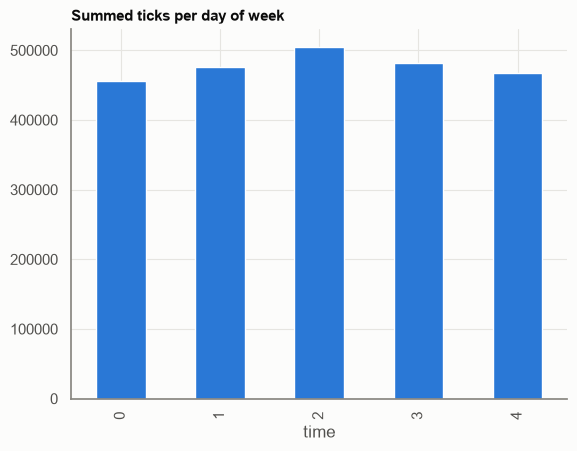

In [84]:
# inspect dataframe
print(frame_summary(ticks))
ticks.index = pd.to_datetime(ticks.index)
dow = ticks.index.day_of_week
# Are days missing?
grouped = ticks.groupby(dow).size()
grouped.plot(kind="bar", title="Summed ticks per day of week")

<Axes: title={'left': 'ticks per hour'}, xlabel='time'>

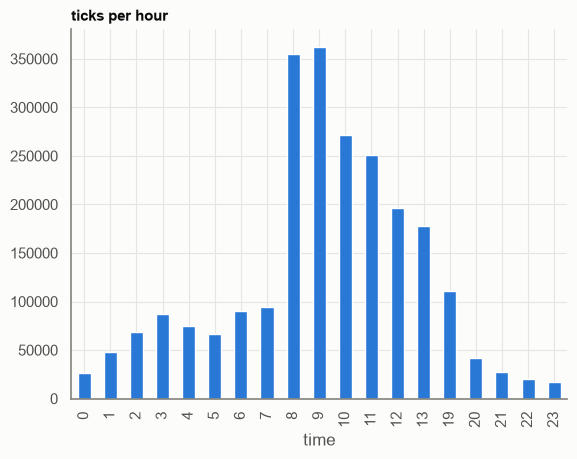

In [76]:
# session hours
cbot = ticks.index.tz_localize("UTC").tz_convert("America/Chicago")
pd.Series(cbot.hour).value_counts().sort_index().plot(kind="bar", title="ticks per hour")

Tick size increments bigger than 0.25
 0


<Axes: ylabel='time'>

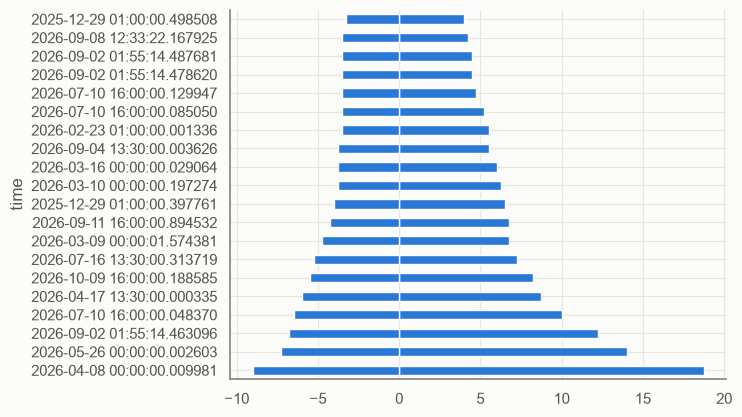

In [81]:
# ticks that are not equal to quarters
print("Tick size increments bigger than 0.25\n", (ticks["price"] % 0.25 != 0).sum())

# largest price moves top 20 to look for roll gaps
rolls = ticks["price"].diff()
rolls.nlargest(20).plot(kind="barh")
rolls.nsmallest(20).plot(kind="barh")


In [57]:
ticks["kind"].nunique()

1